# Generation of miscellaneous networks

Miscellaneous networks (`networkx.Graph` object) can be generated, which can be useful for testing various tools.

**Note.** When a `networkx.Graph` object `G` with position as a node attribute ('pos') is generated, then a `KGraph` object can be defined with `Kg = kn.from_networkx(G)`.


## Percolation networks

Each cell in a grid (array) is activated with a given probability (Bernoulli distribution), which defines a binary array. Then the graph of activate cells, with edges linking adjacent cells, is retrieved.

The functions `kn.misc.random_cluster_in_grid_2d` and `kn.misc.random_cluster_in_grid_3d` allow to generate such networks in 2D and 3D respectively.

In [1]:
import networkx as nx
import numpy as np 
import scipy
import matplotlib.pyplot as plt
import time

In [2]:
# Choose matplotlib backend
# -------------------------
# 'inline' : inline plot (non-interactive)
# 'widget' : interactive plot
# 'tk'     : plot in a pop-up window (interactive)
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
# get_ipython().run_line_magic('matplotlib', 'widget')
# get_ipython().run_line_magic('matplotlib', 'tk')

# Or simply:
# %matplotlib inline
# %matplotlib widget
# %matplotlib tk


In [3]:
import pyvista as pv

# Choose backend for pyvista with jupyter
# ---------------------------------------
pv.set_jupyter_backend('static') # static plots
# pv.set_jupyter_backend('trame')  # 3D-interactive plots

# Notes:
# -> ignored if run in a standard python shell
# -> use keyword argument "notebook=False" in Plotter() to open figure in a pop-up window

In [4]:
import karstnet as kn
print(f'Karstnet version: {kn.__version__}')

Karstnet version: 1.4.6


## Example 1 - 2D

In [8]:
# Example 1

mx, my = 17, 13 # grid size
p = 0.4         # site (cell) activation probability
seed = 8923

g, arr = kn.misc.random_cluster_in_grid_2d(
        mx, my, p, 
        sx=1.0, 
        sy=1.0, 
        seed=seed, 
        extract_connected_components=False,
        # renumbering_nodes=True,
        return_array=True)

# Set connected component labels as node attribute
g = kn.utils.set_connected_component_attribute(g, attr_name='connected_component_label')


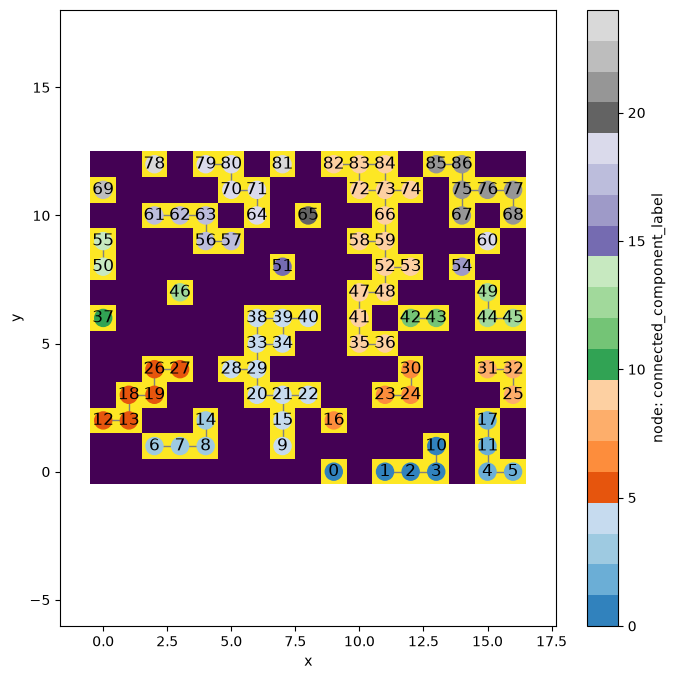

In [9]:
# Plot graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'tab:blue',  # node color (default - if no attribute is specified or for nan values)
    'cmap'        : 'tab20c',    # node color map (for attribute values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

plt.figure(figsize=(8, 8))
plt.imshow(arr, origin='lower', interpolation='none') # comment to hide the matrix
kn.view.plot_graph2d(g, node_attr='connected_component_label', **options)
plt.show()

## Example 2 - 2D

In [10]:
# Example 2
mx, my = 151, 151 # grid size
p = 0.5927        # site (cell) activation probability
                  # close to theoretical percolation threshold for infinite 2D grid
seed = 9528

# Get list of graph correspondin to the connected components
g_list = kn.misc.random_cluster_in_grid_2d(
        mx, my, p, 
        sx=1.0, 
        sy=1.0, 
        seed=seed, 
        extract_connected_components=True,
        renumbering_nodes=True,
        return_array=False)


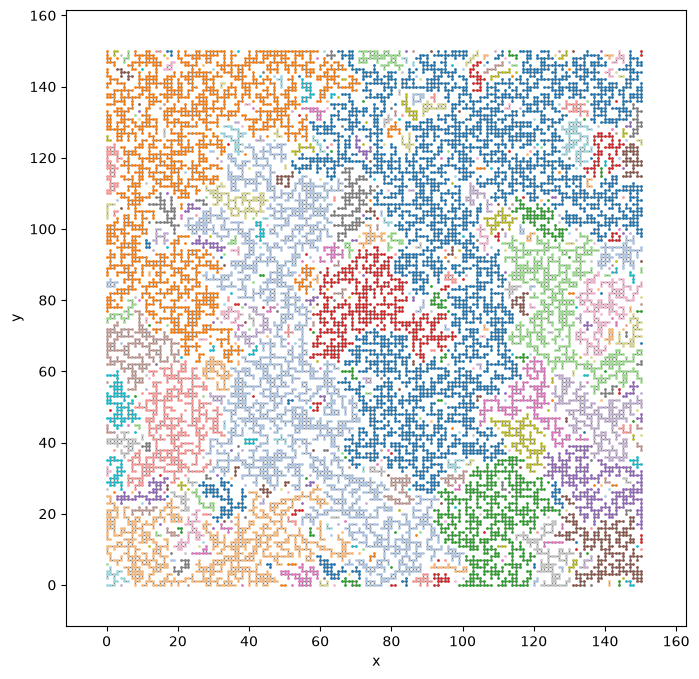

In [11]:
import matplotlib
from matplotlib import colormaps

# Plot graphs
options = {
    'node_size'   : 1,           # node size
    # 'node_color'  : 'tab:blue',  # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,        # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

plt.figure(figsize=(8, 8))
for i, gi in enumerate(g_list):
    options['node_color'] = matplotlib.colors.to_hex(colormaps['tab20'](i%20))
    kn.view.plot_graph2d(gi, **options)
plt.show()

In [12]:
# Get the largest connected component
g = g_list[0]

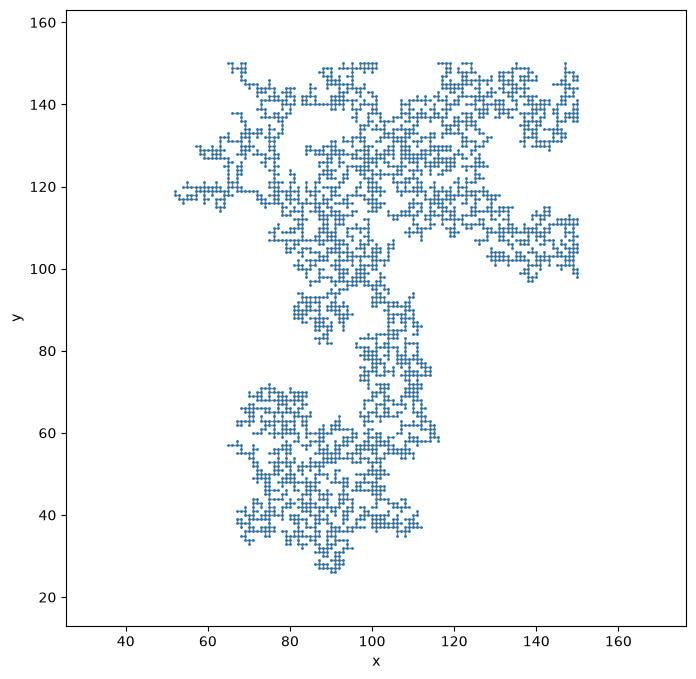

In [13]:
# Plot graph
options = {
    'node_size'   : 1,           # node size
    'node_color'  : 'tab:blue',  # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,        # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.show()

## Example 3 - 3D

In [14]:
# Example 3
mx, my, mz = 61, 61, 61 # grid size
p = 0.3116              # site (cell) activation probability
                        # close to theoretical percolation threshold for infinite 3D grid
seed = 9138

# Get list of graph corresponding to the connected components
g_list = kn.misc.random_cluster_in_grid_3d(
        mx, my, mz, p, 
        sx=1.0, 
        sy=1.0, 
        sz=1.0,
        seed=seed, 
        extract_connected_components=True,
        renumbering_nodes=True,
        return_array=False)

# Get the largest connected component
g = g_list[0]

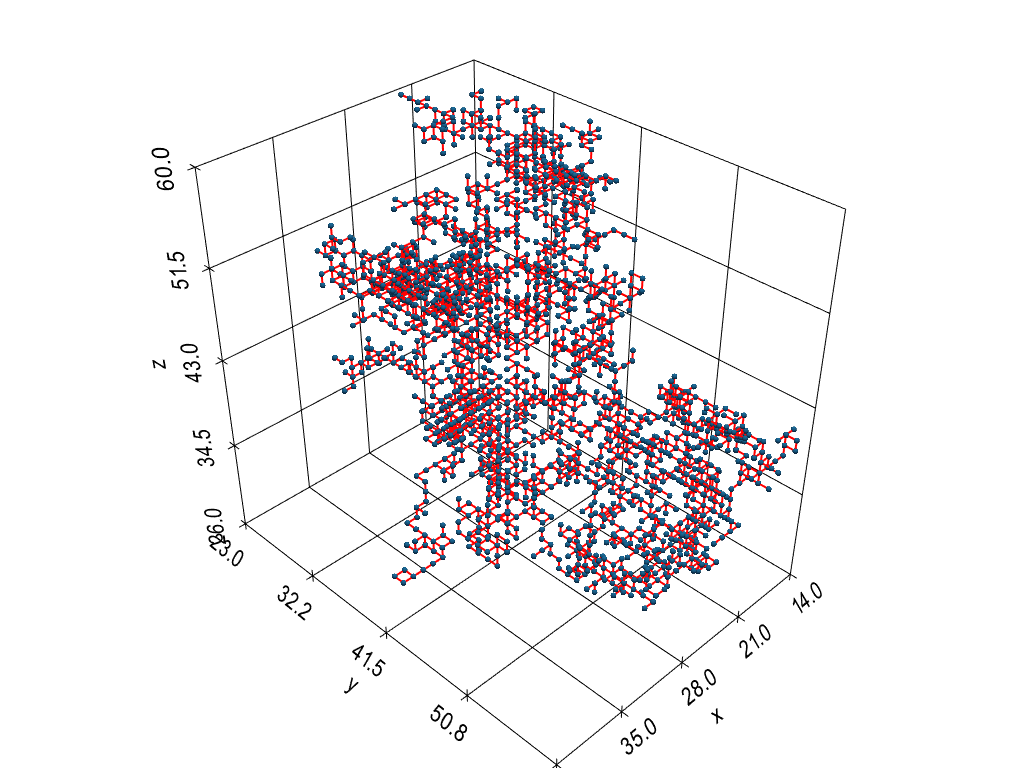

In [15]:
# Plot the graph (based on pyvista)
#pp = pv.Plotter(notebook=False) # plot in a pop-up window
pp = pv.Plotter()

kn.view.pv_plot_graph(
    g,
    plotter=pp,
    options_nodes={'point_size': 6, 'color': 'tab:blue'},
    options_edges={'line_width': 2, 'color': 'red'},
    show_grid=True,
    with_labels=False
)

pp.show()
